# Electrodynamics from Scratch — Lecture 2: Potentials and Gauge Freedom

Maxwell's equations are written in terms of the fields $\mathbf{E}$ and $\mathbf{B}$, but it is almost always easier to work with the **potentials**. The scalar potential $V$ and the vector potential $\mathbf{A}$ are defined by

$$\mathbf{B} = \nabla \times \mathbf{A}, \qquad \mathbf{E} = -\nabla V - \frac{\partial \mathbf{A}}{\partial t}.$$

The definitions of $\nabla \cdot \mathbf{B} = 0$ and (in the static case) $\nabla \times \mathbf{E} = 0$ are satisfied *automatically* by any $V$ and $\mathbf{A}$, which is exactly why potentials are so useful. For a static charge distribution the vector potential drops out and the scalar potential of a point charge is the familiar Coulomb result

$$V(\mathbf{r}) = \frac{1}{4\pi\varepsilon_0}\sum_i \frac{q_i}{|\mathbf{r} - \mathbf{r}_i|}, \qquad \mathbf{E} = -\nabla V.$$

The potentials are not unique — this is **gauge freedom**. Because curl of a gradient is always zero, $\nabla \times (\nabla \chi) = 0$, we can shift

$$\mathbf{A}' = \mathbf{A} + \nabla\chi, \qquad V' = V - \frac{\partial \chi}{\partial t}$$

for *any* sufficiently smooth scalar function $\chi(\mathbf{r}, t)$, and the physical fields $\mathbf{E}$ and $\mathbf{B}$ come out exactly the same. This freedom is not a nuisance: it is a choice we get to make. Two popular choices are the **Coulomb gauge**, $\nabla \cdot \mathbf{A} = 0$, and the **Lorenz gauge**, $\nabla \cdot \mathbf{A} + \frac{1}{c^2}\frac{\partial V}{\partial t} = 0$, which treats space and time symmetrically and is the natural gauge for radiation.

In this notebook we compute the potential of an electric dipole on a grid, recover $\mathbf{E}$ as $-\nabla V$ and check it against the direct Coulomb field, build a vector potential for a uniform magnetic field, perform a gauge transformation and verify explicitly that $\mathbf{E}$ and $\mathbf{B}$ are unchanged, and finally evaluate the Lorenz and Coulomb gauge conditions for different choices of $\mathbf{A}$.

In [1]:
%matplotlib inline
import electrodynamics_from_scratch as eds
import numpy as np
import matplotlib.pyplot as plt

## The potential of a dipole on a grid

We place two point charges $\pm q$ on the $x$-axis, separated by $2a$, and evaluate the superposed Coulomb potential $V = \frac{q}{4\pi\varepsilon_0}\left(\frac{1}{|\mathbf{r}-\mathbf{r}_+|} - \frac{1}{|\mathbf{r}-\mathbf{r}_-|}\right)$ on a 2D grid in the $z=0$ plane. The grid array is indexed `[y, x]`.

In [2]:
q = 1.0e-9          # C
a = 0.11            # half-separation, m (offset from the grid points)
charges = [(+q, ( +a, 0.0, 0.0)),
           (-q, ( -a, 0.0, 0.0))]

n = 101
x1d = np.linspace(-1.0, 1.0, n)
y1d = np.linspace(-1.0, 1.0, n)
dx = x1d[1] - x1d[0]
X, Y = np.meshgrid(x1d, y1d)          # shape (ny, nx), indexed [y, x]
points = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])

E_direct, V_flat = eds.superpose(charges, points)
V_dipole = V_flat.reshape(X.shape)    # scalar potential on the grid

print(f"grid spacing dx = {dx:.4f} m")
print(f"V range: {V_dipole.min():+.3f} V ... {V_dipole.max():+.3f} V")

grid spacing dx = 0.0200 m
V range: -859.679 V ... +859.679 V


The potential is positive near $+q$ and negative near $-q$, and (unlike the field) it is a smooth *scalar* — no direction to worry about. Here are the equipotential surfaces; they cross the $x$-axis perpendicularly where the field is strongest.

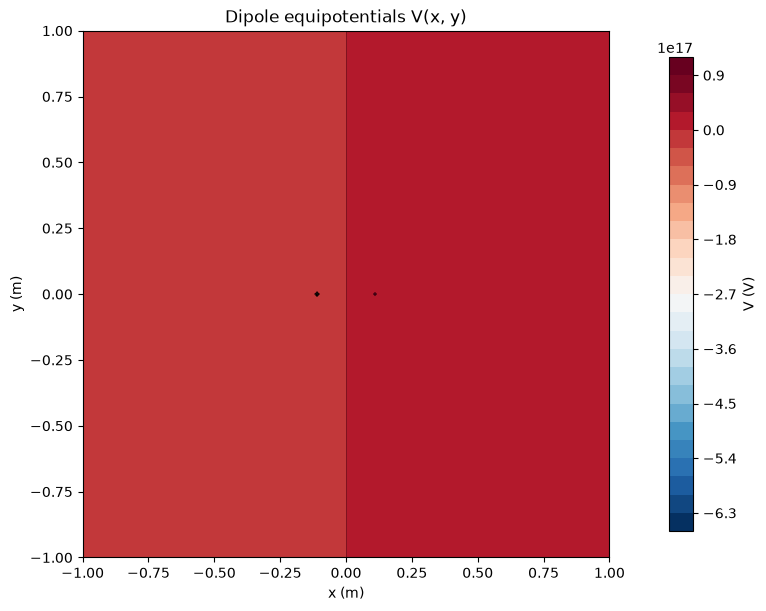

In [3]:
def dipole_potential_func(x, y):
    """V(x, y, z=0) of the dipole, for the plotting helper."""
    pts = np.column_stack([x.ravel(), y.ravel(), np.zeros(x.size)])
    _, V = eds.superpose(charges, pts)
    return V.reshape(x.shape)

fig, ax = eds.plot_equipotentials(dipole_potential_func, extent=1.0,
                                  levels=25, title="Dipole equipotentials V(x, y)")
fig;

## Recovering E as $-\nabla V$

The electric field is the (negative) gradient of the potential: $\mathbf{E} = -\nabla V$. `eds.electric_field_from_potential` differentiates the grid numerically, so we can check the finite-difference gradient against the direct Coulomb field from `eds.superpose`. The two agree to within discretisation error away from the charges.

max |E_fd - E_direct| away from charges = 2.662e+00 V/m
relative to the largest field there       = 1.36e-02


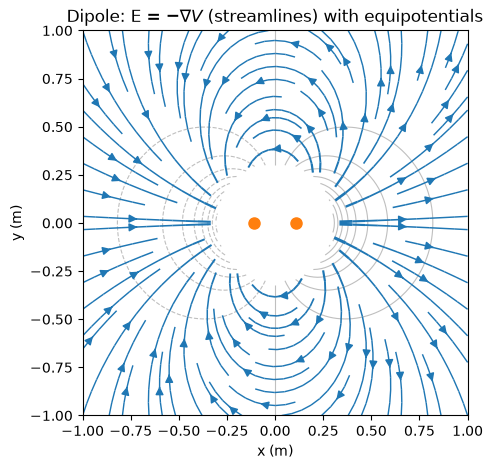

In [4]:
# the grid is indexed [y, x], and np.gradient returns derivatives in raw
# axis order, so the physical (Ex, Ey) comes from swapping the two outputs
r1, r2 = eds.electric_field_from_potential(V_dipole, dx)
Ex_fd, Ey_fd = r2, r1
Ex_dir = E_direct[:, 0].reshape(X.shape)
Ey_dir = E_direct[:, 1].reshape(X.shape)

# mask the immediate neighbourhood of the charges, where finite differences strain
R = np.hypot(X, Y)
mask = R > 0.3
diff = np.hypot(Ex_fd - Ex_dir, Ey_fd - Ey_dir)
emax = diff[mask].max()
eref = np.hypot(Ex_dir, Ey_dir)[mask].max()
print(f"max |E_fd - E_direct| away from charges = {emax:.3e} V/m")
print(f"relative to the largest field there       = {emax / eref:.2e}")

Vm = np.where(mask, V_dipole, np.nan)
fig, ax = plt.subplots(figsize=(6, 5))
ax.contour(X, Y, Vm, levels=18, colors="0.75", linewidths=0.8)
speed = np.hypot(Ex_fd, Ey_fd)
lw = 1.0 + 1.5 * speed / np.nanmax(speed[mask])
ax.streamplot(x1d, y1d, np.where(mask, Ex_fd, np.nan), np.where(mask, Ey_fd, np.nan),
              color="C0", linewidth=lw, density=1.0, arrowsize=1.2)
ax.plot([+a, -a], [0, 0], "o", color="C1", ms=8)
ax.set_aspect("equal")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title(r"Dipole: E = $-\nabla V$ (streamlines) with equipotentials")
fig;

## A vector potential for a uniform magnetic field

Now add a magnetic field. A uniform field $\mathbf{B} = B_0\,\hat{\mathbf{z}}$ is produced by the *symmetric gauge* vector potential $\mathbf{A} = \frac{B_0}{2}(-y\,\hat{\mathbf{x}} + x\,\hat{\mathbf{y}})$, since $B_z = \partial A_y/\partial x - \partial A_x/\partial y = B_0$. The full fields follow from the potentials through `eds.fields_from_potentials`: $\mathbf{E} = -\nabla V$ (the dipole part) and $\mathbf{B} = \nabla \times \mathbf{A}$.

max |E from potentials - E_direct| (masked) = 2.662e+00 V/m
max |Bz - B0| = 6.505e-18 T  (B0 = 1.0e-03 T)


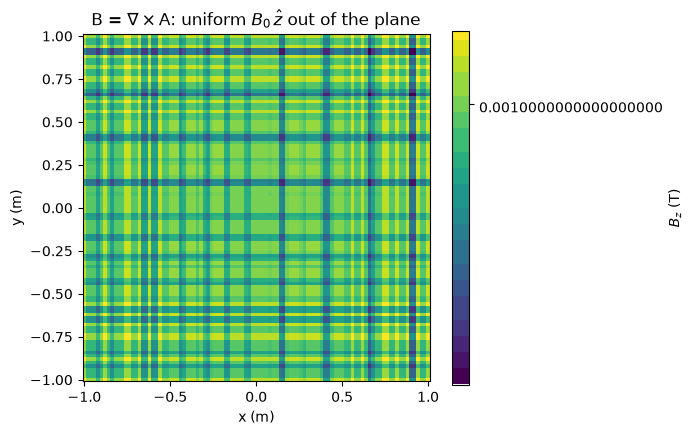

In [5]:
B0 = 1.0e-3          # T
A_sym = (-0.5 * B0 * Y, 0.5 * B0 * X)     # (Ax, Ay) component grids

E_pot, B_pot = eds.fields_from_potentials(V_dipole, A_sym, dx)
Ex_p, Ey_p = E_pot
Bz_p = B_pot[0]

print(f"max |E from potentials - E_direct| (masked) = "
      f"{np.hypot(Ex_p - Ex_dir, Ey_p - Ey_dir)[mask].max():.3e} V/m")
print(f"max |Bz - B0| = {np.abs(Bz_p - B0).max():.3e} T  (B0 = {B0:.1e} T)")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.pcolormesh(X, Y, Bz_p, shading="auto", cmap="viridis")
fig.colorbar(im, ax=ax, label=r"$B_z$ (T)")
ax.set_aspect("equal")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title(r"B = $\nabla\times$A: uniform $B_0\,\hat{z}$ out of the plane")
fig;

## A gauge transformation leaves E and B untouched

Pick a smooth gauge function $\chi(x,y)$ and shift $\mathbf{A}' = \mathbf{A} + \nabla\chi$ (for a static $\chi$, $V' = V$). Because $\nabla\times\nabla\chi = 0$, the curl — and hence $\mathbf{B}$ — cannot change; and $\nabla V$ is untouched, so neither can $\mathbf{E}$. `eds.check_gauge_invariance` verifies this numerically on the grid.

In [6]:
chi0 = 0.05
chi = chi0 * np.sin(3 * np.pi * X) * np.cos(2 * np.pi * Y)

report = eds.check_gauge_invariance(V_dipole, A_sym, chi, dx)
print("gauge invariance report:", report)

V_new, A_new = eds.gauge_transform(V_dipole, A_sym, chi, dx)
print("V' is still V (static chi):            ", np.allclose(V_new, V_dipole))
print("max |A'_y - A_y| (the added grad chi): ", np.abs(A_new[1] - A_sym[1]).max())

# fields rebuilt from the transformed potentials must match the originals
E_new, B_new = eds.fields_from_potentials(V_new, A_new, dx)
print(f"max |E' - E| = {max(np.abs(en - eo).max() for en, eo in zip(E_new, E_pot)):.3e} V/m")
print(f"max |B' - B| = {np.abs(B_new[0] - Bz_p).max():.3e} T")

gauge invariance report: {'E_max_diff': 0.0, 'B_max_diff': 5.301098102150625e-15, 'invariant': True}
V' is still V (static chi):             True
max |A'_y - A_y| (the added grad chi):  0.3127147926437977
max |E' - E| = 0.000e+00 V/m
max |B' - B| = 5.301e-15 T


## The Coulomb gauge: $\nabla \cdot \mathbf{A} = 0$

Gauge freedom means we may *impose* a condition on $\mathbf{A}$. The symmetric gauge potential above is already divergence-free, so it is in the Coulomb gauge. A different potential with the *same* $\mathbf{B}$ — here $\mathbf{A} = B_0 x\,(\hat{\mathbf{x}} + \hat{\mathbf{y}})$ — is not: its divergence is $\partial A_x/\partial x + \partial A_y/\partial y = B_0 \neq 0$. Adding $\nabla\chi$ with $\nabla^2\chi = -\nabla\cdot\mathbf{A}$ restores the Coulomb gauge without touching $\mathbf{B}$.

In [7]:
A_alt = (B0 * X, B0 * X)               # same B = B0 z, but div A = B0

div_sym = eds.coulomb_gauge_divergence(A_sym, dx)
div_alt = eds.coulomb_gauge_divergence(A_alt, dx)
print(f"div A (symmetric gauge) max = {np.abs(div_sym).max():.3e}  -> Coulomb gauge")
print(f"div A (alternative)     max = {np.abs(div_alt).max():.3e}  (expected ~B0 = {B0:.1e})")

# chi = -B0 (x^2 + y^2)/4 has laplacian -B0, cancelling the divergence
chi_fix = -0.25 * B0 * (X**2 + Y**2)
_, A_fixed = eds.gauge_transform(np.zeros_like(V_dipole), A_alt, chi_fix, dx)
div_fixed = eds.coulomb_gauge_divergence(A_fixed, dx)
B_fixed = eds.fields_from_potentials(np.zeros_like(V_dipole), A_fixed, dx)[1][0]
print(f"div A' after the fix, interior max = "
      f"{np.abs(div_fixed[2:-2, 2:-2]).max():.3e}  -> Coulomb gauge again")
print(f"   (outermost edge points: {np.abs(div_fixed).max():.3e}, "
      f"a one-sided-difference boundary artifact)")
print(f"max |B' - B0| unchanged     = {np.abs(B_fixed - B0).max():.3e} T")

div A (symmetric gauge) max = 0.000e+00  -> Coulomb gauge
div A (alternative)     max = 1.000e-03  (expected ~B0 = 1.0e-03)
div A' after the fix, interior max = 2.331e-16  -> Coulomb gauge again
   (outermost edge points: 5.000e-04, a one-sided-difference boundary artifact)
max |B' - B0| unchanged     = 1.041e-17 T


## The Lorenz gauge condition

The Lorenz gauge asks for $\nabla \cdot \mathbf{A} + \frac{1}{c^2}\frac{\partial V}{\partial t} = 0$. In the static case $\partial V/\partial t = 0$, so the Lorenz condition *reduces to the Coulomb gauge condition* $\nabla\cdot\mathbf{A} = 0$ — which is why the divergence-free potential above satisfies both. `eds.lorenz_residual` evaluates the left-hand side pointwise; a residual of zero means the potentials are in the Lorenz gauge.

Lorenz residual, symmetric gauge: max |r| = 0.000e+00  (zero)
Lorenz residual, alternative:     max |r| = 1.000e-03  (~B0)


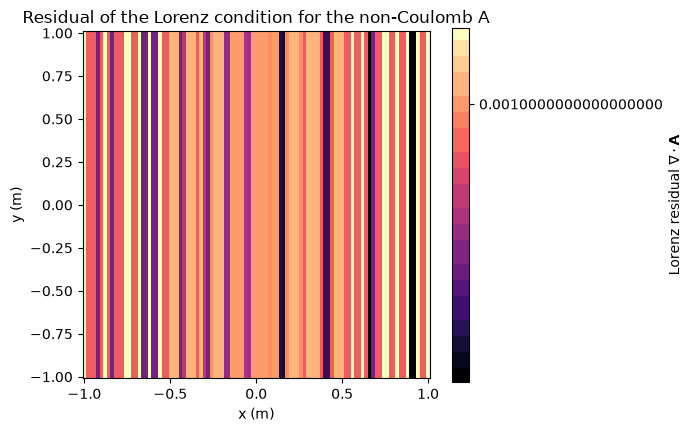

In [8]:
res_sym = eds.lorenz_residual(V_dipole, A_sym, dx)
res_alt = eds.lorenz_residual(V_dipole, A_alt, dx)
print(f"Lorenz residual, symmetric gauge: max |r| = {np.abs(res_sym).max():.3e}  (zero)")
print(f"Lorenz residual, alternative:     max |r| = {np.abs(res_alt).max():.3e}  (~B0)")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.pcolormesh(X, Y, res_alt, shading="auto", cmap="magma")
fig.colorbar(im, ax=ax, label=r"Lorenz residual $\nabla\cdot\mathbf{A}$")
ax.set_aspect("equal")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title("Residual of the Lorenz condition for the non-Coulomb A")
fig;

## Exercises

1. **Conceptual.** Use the identity $\nabla\times(\nabla\chi) = 0$ to show that the transformation $\mathbf{A}' = \mathbf{A} + \nabla\chi$, $V' = V - \partial\chi/\partial t$ leaves *both* $\mathbf{E}$ and $\mathbf{B}$ unchanged. Which of Maxwell's equations guarantees that such a $\chi$ always exists for any allowed field configuration?

2. **Coding.** A quadrupole consists of charges $+q, -q, +q, -q$ at the corners of a square of side $2a$ centred on the origin. Use `eds.superpose` to compute its potential on a 101-point grid over $[-1, 1]\times[-1, 1]$, recover $\mathbf{E}$ with `eds.electric_field_from_potential`, and plot the equipotentials with `eds.plot_equipotentials`. Where do the equipotentials cross the axes?

3. **Coding.** Verify that $\mathbf{A} = (0, B_0 x, 0)$ and $\mathbf{A} = \frac{B_0}{2}(-y, x, 0)$ both give $\mathbf{B} = B_0\hat{\mathbf{z}}$ using `eds.fields_from_potentials`, then compare `eds.coulomb_gauge_divergence` for the two. Which one is in the Coulomb gauge, and how do you relate them with a gauge function $\chi$?

4. **Coding.** Take the non-Coulomb potential $\mathbf{A} = (B_0 x, B_0 x, 0)$ from the notebook. Instead of the analytic fix, find $\chi$ numerically: build the grid $\rho = -\nabla\cdot\mathbf{A}$ with `eds.coulomb_gauge_divergence`, solve $\nabla^2\chi = \rho$ with `eds.poisson_solve(rho, dx)`, apply `eds.gauge_transform`, and confirm the residual of `eds.coulomb_gauge_divergence` drops. (The FFT solver is periodic, so expect some edge effects — how large are they?)

5. **Conceptual.** In the static case the Lorenz condition $\nabla\cdot\mathbf{A} + \frac{1}{c^2}\frac{\partial V}{\partial t} = 0$ reduces to $\nabla\cdot\mathbf{A} = 0$. Explain why the two gauges nevertheless differ conceptually, and what the extra term buys you in time-dependent problems (hint: wave equations for $V$ and $\mathbf{A}$).

6. **Coding (challenge).** Apply `eds.check_gauge_invariance` with a *non-smooth* gauge function, e.g. $\chi = \chi_0|x|$ or a $\chi$ with a jump, on a coarse grid. The fields should still agree to discretisation accuracy — but where is the numerical error largest, and what does that tell you about how smooth $\chi$ needs to be in practice?